In [13]:
from google.colab import files

uploaded = files.upload()

Saving SQUATEX..mp4 to SQUATEX..mp4


In [14]:
import os

print(os.listdir("/content"))

['.config', 'SQUATEX..mp4', 'sample_data']


In [18]:
#Video File Detection and Import
import cv2
import os
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
from google.colab import files

#Find the uploaded video
video_files = [
    f for f in os.listdir("/content")
    if f.lower().endswith((".mp4", ".avi", ".mov", ".mkv"))
]

print("Available videos:", video_files)

Available videos: ['SQUATEX..mp4']


In [ ]:
VIDEO_PATH = "SQUATEX..mp4"

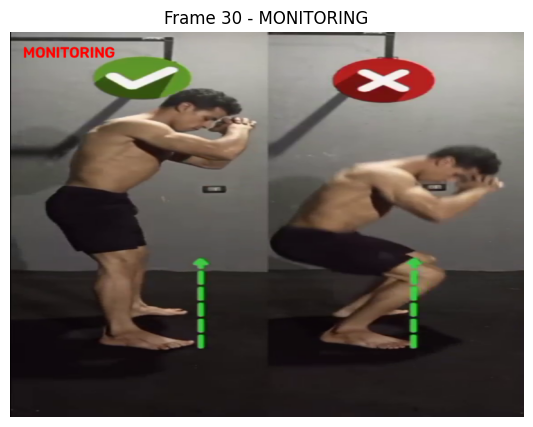

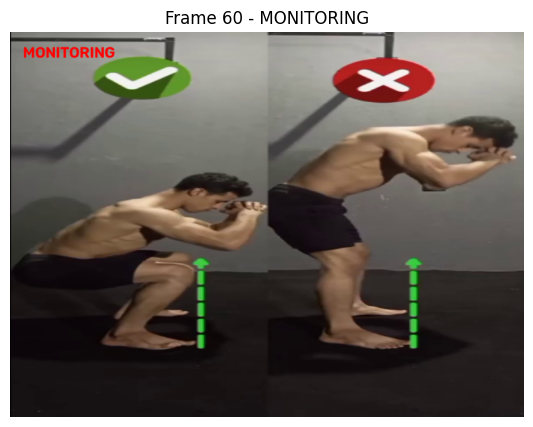

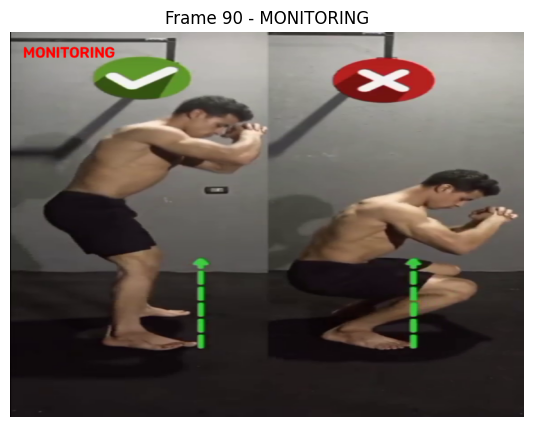

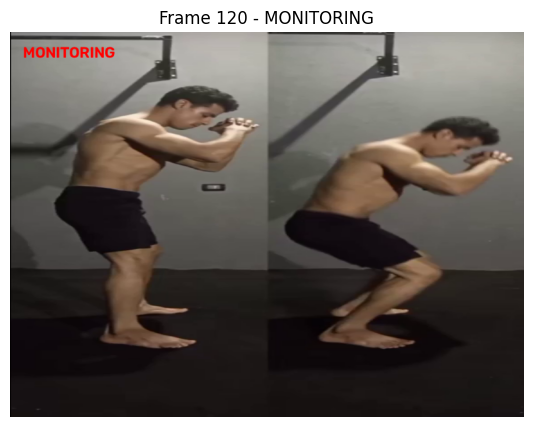

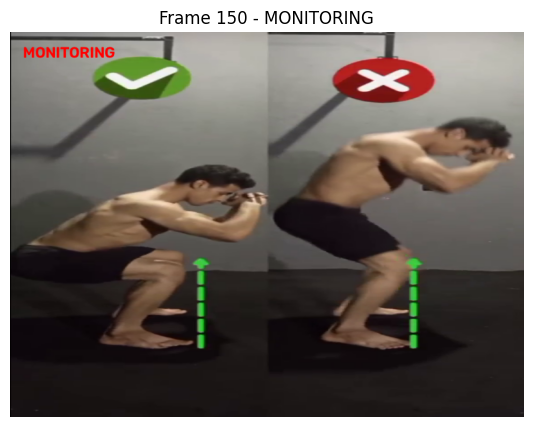

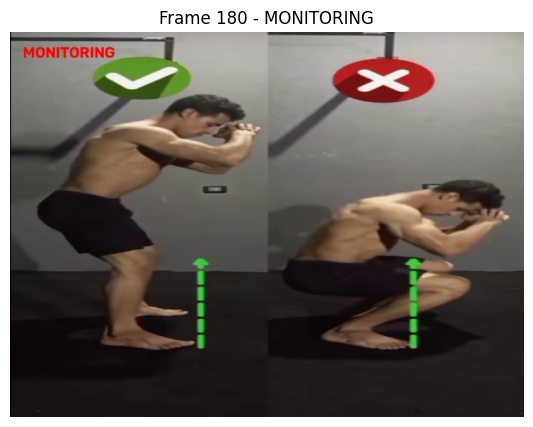

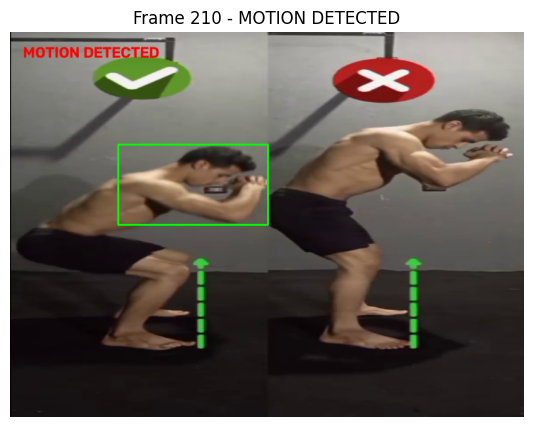

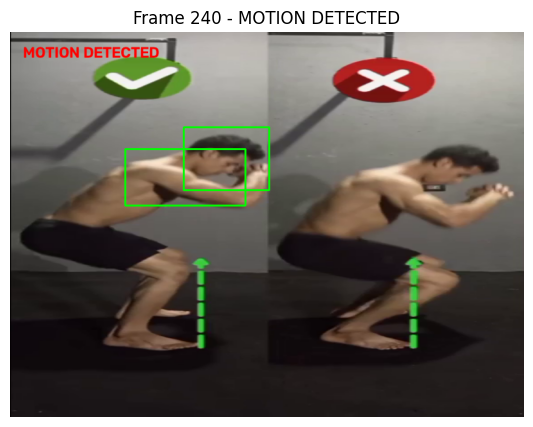

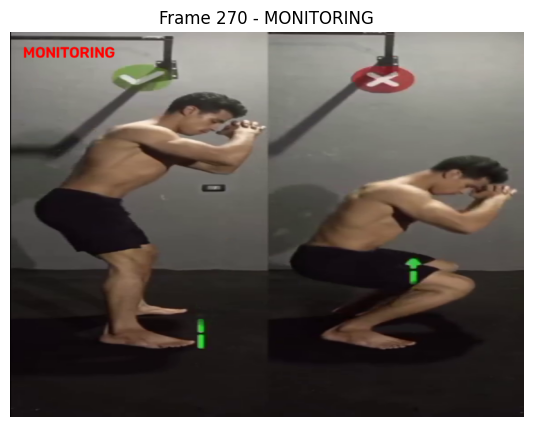

Total frames processed: 271
Frames with detected motion: 108
Motion-frame percentage: 39.85 %


In [17]:
#Motion Detection Processing
import cv2
import matplotlib.pyplot as plt

VIDEO_PATH = "SQUATEX..mp4"

MIN_CONTOUR_AREA = 5000
THRESHOLD_VALUE = 30
DILATION_ITERATIONS = 3

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise ValueError("Cannot open video. Check the filename.")

ret, previous = cap.read()

if not ret:
    raise ValueError("Cannot read the video.")

previous = cv2.resize(previous, (800, 600))
previous_gray = cv2.cvtColor(previous, cv2.COLOR_BGR2GRAY)
previous_gray = cv2.GaussianBlur(previous_gray, (21, 21), 0)

frame_count = 0
motion_frames = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break

    frame = cv2.resize(frame, (800, 600))
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (21, 21), 0)

    difference = cv2.absdiff(previous_gray, gray)

    _, mask = cv2.threshold(
        difference, THRESHOLD_VALUE, 255, cv2.THRESH_BINARY
    )

    mask = cv2.dilate(
        mask, None, iterations=DILATION_ITERATIONS
    )

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    moving_objects = 0

    for contour in contours:
        if cv2.contourArea(contour) < MIN_CONTOUR_AREA:
            continue

        moving_objects += 1
        x, y, w, h = cv2.boundingRect(contour)

        cv2.rectangle(
            frame, (x, y), (x + w, y + h), (0, 255, 0), 2
        )

    if moving_objects > 0:
        motion_frames += 1
        label = "MOTION DETECTED"
    else:
        label = "MONITORING"

    cv2.putText(
        frame, label, (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2
    )

    frame_count += 1

    #Display every 30th frame
    if frame_count % 30 == 0:
        plt.figure(figsize=(10, 5))
        plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        plt.title(f"Frame {frame_count} - {label}")
        plt.axis("off")
        plt.show()

    previous_gray = gray.copy()

cap.release()

print("Total frames processed:", frame_count)
print("Frames with detected motion:", motion_frames)
print("Motion-frame percentage:",
      round(100 * motion_frames / frame_count, 2)
      if frame_count else 0, "%")

In [20]:
#Video file detection and automatic selection
import os
import glob

video_extensions = ["*.mp4", "*.avi", "*.mov", "*.mkv", "*.webm"]
videos = []

for ext in video_extensions:
    videos.extend(glob.glob("/content/" + ext))

print("Available videos:")

for i, video in enumerate(videos):
    print(f"{i}: {os.path.basename(video)}")

if not videos:
    print("Walay video nga nakita sa /content.")
    print("Siguroha nga naa na ang video sa Colab files.")
else:
    VIDEO_PATH = videos[0]
    print("\nSelected video:", VIDEO_PATH)


Available videos:
0: SQUATEX..mp4

Selected video: /content/SQUATEX..mp4


In [22]:
#Motion Detection Testing and Results Comparison (Test A, B, and C)
import cv2
import os
import csv
import pandas as pd
from IPython.display import display, Video

#OUTPUT FOLDER
OUTPUT_DIR = "/content/motion_comparison"
os.makedirs(OUTPUT_DIR, exist_ok=True)

#THREE TEST SETTINGS
SETTINGS = {
    "Test A - Sensitive": {
        "MIN_CONTOUR_AREA": 500,
        "THRESHOLD_VALUE": 20,
        "DILATION_ITERATIONS": 2
    },
    "Test B - Original": {
        "MIN_CONTOUR_AREA": 3000,
        "THRESHOLD_VALUE": 25,
        "DILATION_ITERATIONS": 2
    },
    "Test C - Less Sensitive": {
        "MIN_CONTOUR_AREA": 5000,
        "THRESHOLD_VALUE": 30,
        "DILATION_ITERATIONS": 3
    }
}

#Same frame sampling for every test
FRAME_STEP = 1  #Process every frame
MIN_EVENT_GAP = 10  #Frames between counted motion events

def run_test(video_path, test_name, config):
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise ValueError(f"Cannot open video: {video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps <= 0:
        fps = 30

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    output_path = os.path.join(
        OUTPUT_DIR,
        test_name.replace(" ", "_").replace("-", "") + ".mp4"
    )

    writer = cv2.VideoWriter(
        output_path,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (width, height)
    )

    if not writer.isOpened():
        cap.release()
        raise ValueError("Cannot create output video.")

    min_area = config["MIN_CONTOUR_AREA"]
    threshold_value = config["THRESHOLD_VALUE"]
    dilation_iterations = config["DILATION_ITERATIONS"]

    previous_gray = None
    processed_frames = 0
    detected_frames = 0
    motion_events = 0
    previous_detection = False
    frames_since_event = MIN_EVENT_GAP
    total_boxes = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        processed_frames += 1

        #Grayscale and blur to reduce small image noise
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        gray = cv2.GaussianBlur(gray, (21, 21), 0)

        motion_found = False
        boxes_this_frame = 0

        if previous_gray is not None:
            #Compare current frame with previous frame
            difference = cv2.absdiff(previous_gray, gray)

            _, threshold = cv2.threshold(
                difference,
                threshold_value,
                255,
                cv2.THRESH_BINARY
            )

            threshold = cv2.dilate(
                threshold,
                None,
                iterations=dilation_iterations
            )

            contours, _ = cv2.findContours(
                threshold,
                cv2.RETR_EXTERNAL,
                cv2.CHAIN_APPROX_SIMPLE
            )

            for contour in contours:
                area = cv2.contourArea(contour)

                if area >= min_area:
                    x, y, w, h = cv2.boundingRect(contour)

                    cv2.rectangle(
                        frame,
                        (x, y),
                        (x + w, y + h),
                        (0, 255, 0),
                        2
                    )

                    motion_found = True
                    boxes_this_frame += 1

            total_boxes += boxes_this_frame

        if motion_found:
            detected_frames += 1
            frames_since_event += 1

            if not previous_detection or frames_since_event >= MIN_EVENT_GAP:
                motion_events += 1
                frames_since_event = 0
        else:
            frames_since_event += 1

        previous_detection = motion_found

        label = (
            f"{test_name} | "
            f"Motion: {'DETECTED' if motion_found else 'NONE'}"
        )

        cv2.putText(
            frame, label, (10, 30),
            cv2.FONT_HERSHEY_SIMPLEX, 0.65,
            (0, 255, 0) if motion_found else (255, 255, 255),
            2
        )

        writer.write(frame)
        previous_gray = gray

        if processed_frames % 500 == 0:
            print(f"{test_name}: processed {processed_frames} frames")

    cap.release()
    writer.release()

    detection_rate = (
        detected_frames / processed_frames * 100
        if processed_frames else 0
    )

    return {
        "Test": test_name,
        "Min Contour Area": min_area,
        "Threshold": threshold_value,
        "Dilation": dilation_iterations,
        "Frames Processed": processed_frames,
        "Frames with Motion": detected_frames,
        "Detection Rate (%)": round(detection_rate, 2),
        "Motion Events (approx.)": motion_events,
        "Bounding Boxes": total_boxes,
        "Output Video": output_path
    }

#THREE TESTS
if "VIDEO_PATH" not in globals() or not os.path.isfile(VIDEO_PATH):
    raise FileNotFoundError(
        "Set VIDEO_PATH to the path of your uploaded video first."
    )

results = []

for test_name, config in SETTINGS.items():
    print(f"\nRunning {test_name}...")
    result = run_test(VIDEO_PATH, test_name, config)
    results.append(result)
    print("Finished:", test_name)

#Display comparison table
results_df = pd.DataFrame(results)

display(
    results_df[
        [
            "Test",
            "Min Contour Area",
            "Threshold",
            "Dilation",
            "Frames Processed",
            "Frames with Motion",
            "Detection Rate (%)",
            "Motion Events (approx.)",
            "Bounding Boxes"
        ]
    ]
)

#Saving the result to csv
csv_path = os.path.join(OUTPUT_DIR, "comparison_results.csv")
results_df.to_csv(csv_path, index=False)

print("\nResults saved to:", csv_path)
print("Output folder:", OUTPUT_DIR)



Running Test A - Sensitive...
Finished: Test A - Sensitive

Running Test B - Original...
Finished: Test B - Original

Running Test C - Less Sensitive...
Finished: Test C - Less Sensitive


,Test,Min Contour Area,Threshold,Dilation,Frames Processed,Frames with Motion,Detection Rate (%),Motion Events (approx.),Bounding Boxes
0,Test A - Sensitive,500,20,2,272,231,84.93,44,2106
1,Test B - Original,3000,25,2,272,187,68.75,50,418
2,Test C - Less Sensitive,5000,30,3,272,117,43.01,41,164



Results saved to: /content/motion_comparison/comparison_results.csv
Output folder: /content/motion_comparison


In [10]:

# Video Conversion and Playback

!apt-get -y install ffmpeg -qq

import os
import subprocess
from IPython.display import Video, display

# Add your actual output video filenames here
video_files = [
    "SQUATEX..mp4",
    "SQUATSEX..mp4",
    "SQUATEX..mp4"
]

for input_video in video_files:

    if not os.path.exists(input_video):
        print("Video not found:", input_video)
        continue

    output_video = (
        os.path.splitext(input_video)[0] + "_playable.mp4"
    )

    command = [
        "ffmpeg", "-y",
        "-i", input_video,
        "-vcodec", "libx264",
        "-pix_fmt", "yuv420p",
        "-acodec", "aac",
        "-movflags", "+faststart",
        output_video
    ]

    process = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True
    )

    if (
        process.returncode == 0
        and os.path.exists(output_video)
        and os.path.getsize(output_video) > 0
    ):
        print("\nPlaying:", input_video)
        display(Video(output_video, embed=True, width=640))
    else:
        print("Conversion failed:", input_video)
        print(process.stderr[-1500:])




Video not found: SQUATEX..mp4
Video not found: SQUATSEX..mp4
Video not found: SQUATEX..mp4


In [ ]:
from google.colab import files

files.download("/content/motion_comparison/comparison_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

#Observation Table
import pandas as pd
from IPython.display import display

observation_data = {
    "Observation": [
        "Small movement",
        "Large movement",
        "Slow movement",
        "False detections",
        "Bounding box accuracy"
    ],
    "Test A - Sensitive": [
        "Detected",
        "Detected",
        "Detected",
        "Few",
        "Good"
    ],
    "Test B - Original": [
        "Detected",
        "Detected",
        "Detected",
        "Few",
        "Good"
    ],
    "Test C - Less Sensitive": [
        "Not detected",
        "Detected",
        "Detected",
        "Few",
        "Good"
    ]
}

observation_df = pd.DataFrame(observation_data)

display(observation_df)


,Observation,Test A - Sensitive,Test B - Original,Test C - Less Sensitive
0,Small movement,Detected,Detected,Not detected
1,Large movement,Detected,Detected,Detected
2,Slow movement,Detected,Detected,Detected
3,False detections,Few,Few,Few
4,Bounding box accuracy,Good,Good,Good
